# Bài 7 · Mô hình chuỗi: RNN, LSTM, GRU và nút thắt của encoder–decoder

**Thời lượng gợi ý:** 180 phút · **Cần:** Bài 6 · **Chạy được trên CPU**

## Mục tiêu

1. Hiểu vì sao ngôn ngữ cần mô hình **có thứ tự** và cách RNN mang "bộ nhớ" qua các bước.
2. Tự cài **ô RNN** bằng NumPy và *đo* hiện tượng **gradient biến mất/bùng nổ**.
3. Hiểu cổng của **LSTM/GRU** là giải pháp cho vấn đề đó; dùng `nn.LSTM`/`nn.GRU` hai chiều cho phân loại.
4. Dùng **gradient clipping** và đệm/gói chuỗi (`pack_padded_sequence`) đúng cách.
5. Tự trải nghiệm **nút thắt** của mô hình encoder–decoder — động lực trực tiếp của *attention* (Bài 8).

In [1]:
import sys, pathlib

ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

from nlpvi import LABELS, load_splits, load_hard, normalize, set_seed
from nlpvi.textnn import build_vocab, TextDS, evaluate, fit

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
set_seed(42)
device = "cpu"
train, valid, test = load_splits()
hard = load_hard()
CLASSES = sorted(LABELS); c2i = {c: i for i, c in enumerate(CLASSES)}
itos, stoi = build_vocab(train["text"])
ds_tr, ds_va, ds_hard = (TextDS(d, stoi, c2i) for d in (train, valid, hard))
V = len(itos)
print("V =", V, "| các hàm huấn luyện lấy từ nlpvi/textnn.py (đã viết từng bước ở Bài 6)")

V = 473 | các hàm huấn luyện lấy từ nlpvi/textnn.py (đã viết từng bước ở Bài 6)


## 1. Vì sao cần mô hình có thứ tự?

Mô hình ở Bài 6 hoặc *mất* thứ tự (trung bình embedding) hoặc chỉ thấy cụm ngắn cố định (CNN). Nhưng ý nghĩa nhiều khi nằm ở **quan hệ xa**:

- *"Món ăn **không** những ngon **mà còn** rẻ"* — phủ định cách động từ cả mấy từ.
- *"Giao hàng chậm, đóng gói ẩu, **nhưng** chất lượng thì tuyệt"* — vế sau quyết định, cách vế trước nhiều từ.

**RNN (Recurrent Neural Network)** đọc từng từ theo thứ tự và giữ một **vector trạng thái ẩn** $\mathbf{h}_t$ như "bộ nhớ" tóm tắt những gì đã đọc:

$$\mathbf{h}_t=\tanh\!\big(W_{xh}\,\mathbf{x}_t+W_{hh}\,\mathbf{h}_{t-1}+\mathbf{b}\big)$$

Cùng một bộ trọng số được dùng ở **mọi bước** (chia sẻ tham số theo thời gian).

## 2. Ô RNN bằng NumPy

In [2]:
rng = np.random.default_rng(0)
d_in, d_h = 4, 5
Wxh = rng.normal(0, 0.6, (d_h, d_in))
Whh = rng.normal(0, 0.6, (d_h, d_h))
b = np.zeros(d_h)

xs = rng.normal(size=(6, d_in))            # 6 "từ", mỗi từ là vector 4 chiều
h = np.zeros(d_h)
H = []
for t, x in enumerate(xs):
    h = np.tanh(Wxh @ x + Whh @ h + b)
    H.append(h)

pd.DataFrame(np.array(H), index=[f"sau từ {t + 1}" for t in range(6)],
             columns=[f"h{j + 1}" for j in range(d_h)]).round(2)

,h1,h2,h3,h4,h5
sau từ 1,0.62,0.99,-0.93,-0.96,0.89
sau từ 2,0.77,-0.67,-0.76,-0.67,-0.89
sau từ 3,-0.54,0.71,-0.08,-0.95,-0.95
sau từ 4,-0.19,-0.89,0.57,-0.95,-0.05
sau từ 5,-0.92,0.70,-0.65,0.89,-0.47
sau từ 6,0.85,0.91,-0.67,-0.91,0.93


Trạng thái ẩn sau từ thứ *t* là hàm của **tất cả các từ từ 1 đến t**. Với phân loại, ta dùng trạng thái cuối (hoặc gộp các trạng thái, xem mục 4) làm biểu diễn cả câu.

## 3. Vấn đề cốt lõi: gradient biến mất và bùng nổ

Để học được quan hệ xa, lỗi ở bước cuối phải truyền ngược về các bước đầu. Gradient đi qua $T$ bước là **tích của $T$ ma trận Jacobi**:

$$\frac{\partial \mathbf{h}_T}{\partial \mathbf{h}_1}=\prod_{t=2}^{T}\operatorname{diag}(1-\mathbf{h}_t^2)\,W_{hh}$$

Nếu các ma trận này "co" (giá trị riêng < 1), tích tiến về 0 theo cấp số mũ → **gradient biến mất**: mô hình không học được quan hệ xa. Nếu "giãn" (> 1) thì bùng nổ. Ta đo trực tiếp bằng thực nghiệm: đặt bán kính phổ $\rho$ của $W_{hh}$ rồi vẽ $\log_{10}\lVert \partial \mathbf{h}_T/\partial \mathbf{h}_1\rVert$ theo độ dài chuỗi.

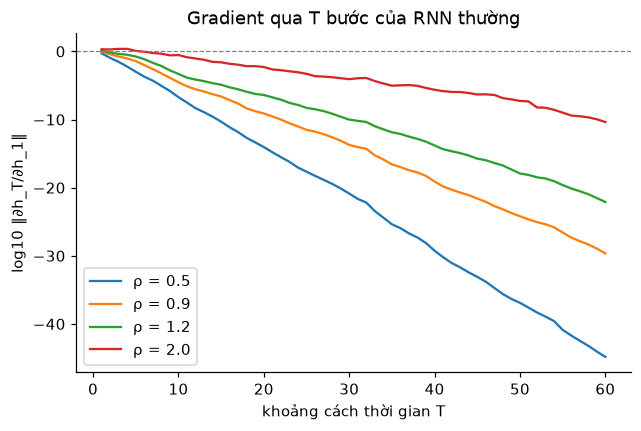

In [3]:
def log_norm_jacobian(rho, T=60, h=32, seed=0, input_scale=0.5):
    rng = np.random.default_rng(seed)
    W = rng.normal(size=(h, h))
    W *= rho / np.max(np.abs(np.linalg.eigvals(W)))      # đặt bán kính phổ = rho
    Wx = rng.normal(size=(h, h)) * input_scale
    hs, J, out = np.zeros(h), np.eye(h), []
    for _ in range(T):
        hs = np.tanh(Wx @ rng.normal(size=h) + W @ hs)
        J = (np.diag(1 - hs ** 2) @ W) @ J
        out.append(np.log10(np.linalg.norm(J, 2) + 1e-300))
    return out

plt.figure(figsize=(6.5, 4))
for rho in [0.5, 0.9, 1.2, 2.0]:
    plt.plot(range(1, 61), log_norm_jacobian(rho), label=f"ρ = {rho}")
plt.axhline(0, color="gray", lw=.8, ls="--")
plt.xlabel("khoảng cách thời gian T"); plt.ylabel("log10 ‖∂h_T/∂h_1‖")
plt.title("Gradient qua T bước của RNN thường"); plt.legend(); plt.show()

**Cả bốn đường đều đi xuống**: tín hiệu từ bước đầu **tắt dần theo cấp số mũ**. Với $\rho\le 1{,}2$, sau 30 bước chuẩn gradient đã chỉ còn cỡ $10^{-10}$ hoặc nhỏ hơn, nên bước đầu gần như không nhận được tín hiệu học. Ngay cả khi $\rho=2$ (đáng lẽ phải *bùng nổ*), nó vẫn tụt xuống ≈$10^{-4}$ sau 30 bước và ≈$10^{-10}$ sau 60 bước, vì tanh **bão hòa** làm hệ số $(1-\mathbf{h}^2)$ rất nhỏ và tự kìm hãm. Vì vậy trong thực tế **biến mất** là vấn đề thường trực, còn **bùng nổ** xuất hiện từng đợt (một batch khó làm chuẩn gradient vọt lên). Bùng nổ xử lý đơn giản bằng **gradient clipping**; biến mất cần một kiến trúc khác.

## 4. LSTM và GRU: có cổng để giữ thông tin

**LSTM** (Hochreiter & Schmidhuber, 1997) thêm một **ô nhớ** $\mathbf{c}_t$ được cập nhật chủ yếu bằng *cộng*, kèm ba cổng (giá trị từ 0 đến 1) quyết định *quên gì, nhận gì, xuất gì*:

$$\begin{aligned}
\mathbf{f}_t&=\sigma(W_f[\mathbf{h}_{t-1},\mathbf{x}_t]) &&\text{cổng quên}\\
\mathbf{i}_t&=\sigma(W_i[\mathbf{h}_{t-1},\mathbf{x}_t]) &&\text{cổng nhập}\\
\tilde{\mathbf{c}}_t&=\tanh(W_c[\mathbf{h}_{t-1},\mathbf{x}_t]) \\
\mathbf{c}_t&=\mathbf{f}_t\odot\mathbf{c}_{t-1}+\mathbf{i}_t\odot\tilde{\mathbf{c}}_t &&\text{ô nhớ: cộng, không nhân ma trận}\\
\mathbf{h}_t&=\sigma(W_o[\mathbf{h}_{t-1},\mathbf{x}_t])\odot\tanh(\mathbf{c}_t)
\end{aligned}$$

Mấu chốt: đường đi của $\mathbf{c}_t$ là `nhân từng phần tử với cổng quên rồi cộng` chứ không qua một ma trận $W$ ở mỗi bước. Nếu cổng quên ≈ 1, thông tin (và gradient) đi *xuyên suốt* nhiều bước gần như không suy giảm.

**GRU** (Cho và cộng sự, 2014) gộp ô nhớ và trạng thái ẩn, chỉ còn hai cổng → ít tham số hơn, thường chất lượng tương đương.

In [4]:
for ten, cls in [("RNN", nn.RNN), ("GRU", nn.GRU), ("LSTM", nn.LSTM)]:
    m = cls(64, 64, batch_first=True)
    print(f"{ten:5s} (64→64): {sum(p.numel() for p in m.parameters()):>6,} tham số")

RNN   (64→64):  8,320 tham số
GRU   (64→64): 24,960 tham số
LSTM  (64→64): 33,280 tham số


### Mô hình phân loại: BiLSTM/BiGRU + max-pooling

- **Hai chiều (bidirectional)**: đọc xuôi và ngược rồi nối lại, nên mỗi vị trí biết cả ngữ cảnh *trước* lẫn *sau*. Với phân loại cả câu (đã có đủ câu), đây thường là cải thiện miễn phí.
- **`pack_padded_sequence`**: để RNN **không** xử lý ô đệm (nếu không, trạng thái cuối của câu ngắn bị "pha" bởi các số 0).
- **Max-pooling theo thời gian**: lấy giá trị lớn nhất mỗi chiều trên toàn câu, thay vì chỉ dùng trạng thái cuối — tín hiệu khỏi phải đi qua cả chuỗi.

In [5]:
class RNNPhanLoai(nn.Module):
    def __init__(self, V, kieu="lstm", d=64, h=64, n_cls=3, p=0.4):
        super().__init__()
        self.emb = nn.Embedding(V, d, padding_idx=0)
        cls = {"lstm": nn.LSTM, "gru": nn.GRU}[kieu]
        self.rnn = cls(d, h, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(p)
        self.fc = nn.Linear(2 * h, n_cls)

    def forward(self, x):
        mask = (x != 0)
        lengths = mask.sum(1).clamp(min=1).cpu()
        packed = pack_padded_sequence(self.emb(x), lengths, batch_first=True, enforce_sorted=False)
        out, _ = self.rnn(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
        out = out.masked_fill(~mask.unsqueeze(-1), -1e9)       # loại ô đệm khỏi max-pooling
        return self.fc(self.drop(out.max(dim=1).values))

set_seed(0)
t0 = time.time()
m = RNNPhanLoai(V, "lstm")
hist = fit(m, ds_tr, ds_va, clip=1.0)
print(f"BiLSTM: {len(hist)} epoch, {time.time() - t0:.1f}s, macro-F1 valid tốt nhất = {hist['f1_valid'].max():.3f}")

BiLSTM: 16 epoch, 9.0s, macro-F1 valid tốt nhất = 0.935


### Gradient clipping

Chuẩn gradient `‖g‖` đôi khi nhảy vọt (do một batch khó). `clip_grad_norm_(params, 1.0)` co `g` về `g × 1/‖g‖` nếu `‖g‖ > 1`: giữ hướng, giới hạn bước đi. Hàm `fit(..., clip=1.0)` đã gọi nó. Cách này gần như miễn phí và nên bật mặc định cho RNN.

### So sánh nhiều seed

In [6]:
def macro_f1(model, ds):
    return evaluate(model, ds, device)[1]

kq = {"BiLSTM": [], "BiGRU": []}
for seed in range(3):
    for ten, kieu in [("BiLSTM", "lstm"), ("BiGRU", "gru")]:
        set_seed(seed)
        mm = RNNPhanLoai(V, kieu)
        fit(mm, ds_tr, ds_va, seed=seed, clip=1.0)
        kq[ten].append((macro_f1(mm, ds_va), macro_f1(mm, ds_hard)))

tf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=r"(?u)\b\w+\b")
lr = LogisticRegression(C=10, max_iter=3000).fit(tf.fit_transform(train["text"].map(normalize)), train["label"])
f_v = f1_score(valid["label"], lr.predict(tf.transform(valid["text"].map(normalize))), average="macro")
f_h = f1_score(hard["label"], lr.predict(tf.transform(hard["text"].map(normalize))), average="macro")

rows = [{"mô hình": k, "valid macro-F1": f"{np.mean([a for a, _ in v]):.3f} ± {np.std([a for a, _ in v]):.3f}",
         "câu khó macro-F1": f"{np.mean([b for _, b in v]):.3f} ± {np.std([b for _, b in v]):.3f}"} for k, v in kq.items()]
rows.append({"mô hình": "TF-IDF + LR (Bài 3)", "valid macro-F1": f"{f_v:.3f}", "câu khó macro-F1": f"{f_h:.3f}"})
pd.DataFrame(rows)

,mô hình,valid macro-F1,câu khó macro-F1
0,BiLSTM,0.932 ± 0.006,0.566 ± 0.012
1,BiGRU,0.931 ± 0.003,0.508 ± 0.010
2,TF-IDF + LR (Bài 3),0.886,0.563


So với Bài 6 (CNN ≈ 0,91, trung bình embedding ≈ 0,88, TF-IDF + LR ≈ 0,89 trên valid), ta thấy:

1. **Trên valid, mô hình có thứ tự vượt rõ**: BiLSTM/BiGRU ≈ 0,93, cao hơn CNN khoảng 0,02 và cao hơn LR khoảng 0,045 — đều lớn hơn nhiều độ lệch chuẩn qua seed (≈ 0,005). Ở đây thứ tự giúp thật.
2. **Trên câu khó thì không**: BiLSTM chỉ ngang TF-IDF + LR (≈ 0,57), còn BiGRU thấp hơn (≈ 0,51). Mô hình học được *khuôn câu* của dữ liệu tổng hợp tốt hơn, chứ chưa học được cách xử lý phủ định/mỉa mai nói chung. Kho huấn luyện chỉ 1.262 mẫu quá nhỏ để học điều đó, và 40 câu khó cũng quá ít để kết luận chắc.

Bài học: điểm cao trên tập cùng phân phối **chưa phải** bằng chứng cho khả năng hiểu ngôn ngữ.

## 5. Seq2seq và nút thắt thông tin

Nhiều bài toán là **chuỗi → chuỗi**: dịch máy, tóm tắt, chatbot. Kiến trúc kinh điển (Sutskever và cộng sự, 2014): một **encoder** RNN đọc cả câu nguồn rồi nén vào **một vector cố định** (trạng thái ẩn cuối), một **decoder** RNN sinh từng từ đích từ vector đó.

```
nguồn:  x1 x2 x3 ... xn  ──encoder──►  [ h_n ]  ──decoder──►  y1 y2 ... ym
                                         ▲ MỘT vector cho mọi độ dài câu
```

Nghi vấn: câu càng dài, một vector cố định càng khó chứa hết. Ta kiểm chứng bằng một bài toán **đồ chơi nhưng sạch**: *đảo ngược chuỗi chữ số* ("3 1 4 1 5" → "5 1 4 1 3"). Bài này không cần hiểu ngôn ngữ — chỉ cần nhớ chính xác, nên mọi thất bại đều quy về khả năng nhớ của mô hình.

In [7]:
VOC, BOS = 10, 10          # chữ số 0-9; token BOS = 10
class Seq2SeqGRU(nn.Module):
    def __init__(self, d=64, h=128):
        super().__init__()
        self.emb = nn.Embedding(VOC + 1, d)
        self.enc = nn.GRU(d, h, batch_first=True)
        self.dec = nn.GRU(d, h, batch_first=True)
        self.out = nn.Linear(h, VOC)

    def forward(self, x, y_in):
        _, h = self.enc(self.emb(x))             # h: (1, B, H) — "toàn bộ câu nguồn" bị nén vào đây
        o, _ = self.dec(self.emb(y_in), h)
        return self.out(o)

    @torch.no_grad()
    def doc_thang(self, x):
        _, h = self.enc(self.emb(x))
        y = torch.full((x.size(0), 1), BOS)
        outs = []
        for _ in range(x.size(1)):
            o, h = self.dec(self.emb(y), h)
            y = self.out(o[:, -1]).argmax(-1, keepdim=True)
            outs.append(y)
        return torch.cat(outs, 1)

def lay_batch(B, L, g):
    x = torch.randint(0, 10, (B, L), generator=g)
    y = x.flip(1)
    y_in = torch.cat([torch.full((B, 1), BOS), y[:, :-1]], 1)     # teacher forcing
    return x, y, y_in

def chinh_xac_theo_do_dai(model, lengths=(4, 8, 12, 16, 20, 24), n=500, seed=123):
    g = torch.Generator().manual_seed(seed)
    res = {}
    model.eval()
    for L in lengths:
        x, y, _ = lay_batch(n, L, g)
        pred = model.doc_thang(x)
        res[L] = (pred == y).all(1).float().mean().item()      # khớp TOÀN BỘ chuỗi
    return res

def huan_luyen_seq2seq(model, steps=3000, seed=0, L_range=(3, 16)):
    set_seed(seed)
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    for step in range(steps):
        L = int(torch.randint(L_range[0], L_range[1] + 1, (1,), generator=g))
        x, y, y_in = lay_batch(64, L, g)
        loss = F.cross_entropy(model(x, y_in).reshape(-1, VOC), y.reshape(-1))
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
    return loss.item()

t0 = time.time()
s2s = Seq2SeqGRU()
loss_cuoi = huan_luyen_seq2seq(s2s)
print(f"Huấn luyện xong trong {time.time() - t0:.0f}s, loss cuối = {loss_cuoi:.3f}")
acc_gru = chinh_xac_theo_do_dai(s2s)
pd.DataFrame({"độ dài chuỗi": list(acc_gru), "tỉ lệ đảo đúng toàn bộ chuỗi": [round(v, 3) for v in acc_gru.values()]}).set_index("độ dài chuỗi").T

Huấn luyện xong trong 30s, loss cuối = 0.392


độ dài chuỗi,4,8,12,16,20,24
tỉ lệ đảo đúng toàn bộ chuỗi,1.0,0.942,0.392,0.022,0.0,0.0


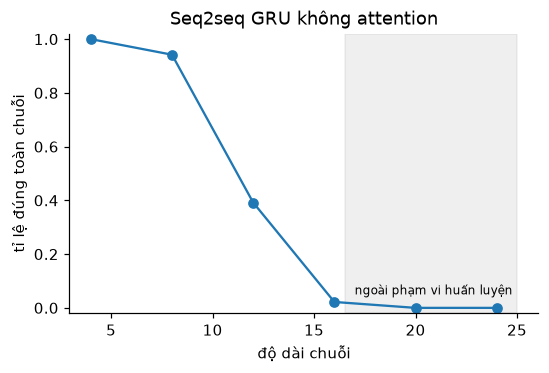

In [8]:
plt.figure(figsize=(5.5, 3.3))
plt.plot(list(acc_gru), list(acc_gru.values()), marker="o")
plt.axvspan(16.5, 25, color="gray", alpha=.12); plt.text(17, 0.05, "ngoài phạm vi huấn luyện", fontsize=8)
plt.xlabel("độ dài chuỗi"); plt.ylabel("tỉ lệ đúng toàn chuỗi"); plt.ylim(-0.02, 1.02)
plt.title("Seq2seq GRU không attention"); plt.show()

**Đọc đồ thị.** Độ chính xác (đảo đúng *toàn bộ* chuỗi) là 100% ở độ dài 4, ≈94% ở độ dài 8, chỉ còn ≈39% ở độ dài 12 và gần 0 từ độ dài 16, dù các độ dài 12–16 vẫn **nằm trong** phạm vi huấn luyện (3–16); vùng xám là độ dài mô hình chưa từng thấy. Toàn bộ nội dung chuỗi nguồn phải chui qua một vector 128 chiều, và gradient phải đi ngược qua cả encoder lẫn decoder dài. Hai yếu tố cùng góp: *lượng thông tin* dồn vào một vector, và *độ khó học* để dồn thông tin ấy. Huấn luyện lâu hơn hoặc vector lớn hơn sẽ đẩy ngưỡng ra xa nhưng không xóa được nút thắt.

Khi dịch máy, vấn đề y hệt: câu nguồn dài thì chất lượng giảm. Lời giải (Bahdanau và cộng sự, 2014) là cho decoder **nhìn lại toàn bộ trạng thái encoder ở mỗi bước** và *chọn chỗ cần chú ý*: đó là **attention**, chủ đề của Bài 8 — nơi ta sẽ huấn luyện đúng bài toán này lại với attention và so sánh.

## 6. Tổng kết

- RNN mang trạng thái ẩn qua các bước; trọng số được chia sẻ theo thời gian.
- Gradient qua nhiều bước là **tích Jacobi** nên biến mất/bùng nổ; LSTM/GRU dùng đường cộng có cổng để giữ thông tin xa; clipping xử lý bùng nổ.
- Với phân loại: BiLSTM/BiGRU + **pack/mask** + max-pooling là công thức mạnh trước thời Transformer.
- Với dữ liệu nhỏ, mô hình có thứ tự không tự động vượt mô hình đơn giản.
- Encoder–decoder có **nút thắt**: một vector cho cả câu nguồn → cần attention.

## Bài tập

1. **(Dễ)** Chạy `log_norm_jacobian` với `input_scale` = 0.1 và 2.0. Đường cong đổi ra sao? Vì sao?
2. **(Dễ)** Đổi `hidden` của `Seq2SeqGRU` từ 128 lên 256. Ngưỡng độ dài mà độ chính xác bắt đầu tụt có dịch đi không?
3. **(Vừa)** Cho encoder **hai chiều** rồi nối hai trạng thái cuối làm khởi tạo decoder. Có cải thiện không? Vì sao?
4. **(Vừa)** Bỏ `pack_padded_sequence` trong `RNNPhanLoai` (chỉ dùng mặt nạ ở pooling). Kết quả khác bao nhiêu? Với RNN **một chiều** và trạng thái cuối, ảnh hưởng sẽ lớn hơn hay nhỏ hơn?
5. **(Khó)** Cài **LSTM cell** bằng NumPy theo công thức trên và so với `nn.LSTMCell` (sao chép trọng số). Chú ý thứ tự cổng trong PyTorch là `i, f, g, o`.

<details>
<summary><b>Gợi ý đáp án</b></summary>

1. `input_scale` lớn làm tanh bão hòa → `1-h²` nhỏ → gradient co nhanh hơn; nhỏ thì trạng thái gần 0 nên `1-h²≈1` và đường cong phụ thuộc chủ yếu vào ρ.
2. Hidden lớn chứa được nhiều thông tin hơn nên ngưỡng dịch sang phải, nhưng vẫn tụt vì nút thắt không biến mất, chỉ rộng ra.
3. Có thể cải thiện nhẹ vì trạng thái nối giàu hơn; nhưng vẫn là nén toàn câu vào một vector.
4. Không pack: trạng thái cuối của RNN một chiều bị "trôi" qua ô đệm, hại nhiều hơn; với max-pooling + mặt nạ ảnh hưởng nhỏ.
5. `gates = W_ih x + b_ih + W_hh h + b_hh`, chia 4 phần theo thứ tự `i, f, g, o`; `c' = f*c + i*tanh(g)`; `h' = o*tanh(c')`.
</details>

**Tiếp theo → Bài 8:** Attention và Transformer từ đầu.

**Đọc thêm:** Christopher Olah, *Understanding LSTM Networks* (2015) · Bahdanau và cộng sự, *Neural Machine Translation by Jointly Learning to Align and Translate* (2014) · [Hugging Face NLP Course, Chương 1 (tiếng Việt)](https://huggingface.co/docs/course/vi/chapter1/1)